<a href="https://colab.research.google.com/github/abusaleh917/Practice/blob/main/UAVIDS_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Install boosting libraries
!pip install xgboost lightgbm catboost -q

In [3]:
#Lode libraries
#core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#preprocessing and model selection
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

#Ensemble Models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score,
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 20   # same seed everywhere -> reproducible results


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
df = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks_Data_Science/UAVIDS-2025.csv')
df.head()

,FlowID,FlowDuration/s,SrcAddr,SrcPort,DstAddr,DstPort,Protocol,TxPackets,RxPackets,LostPackets,...,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount,label
0,1,175.007,192.168.0.150,9,192.168.0.16,9,UDP,251,215,36,...,1.22853,109.002,93.3679,0.022152,0.024406,0.746943,76,0.143426,0.074419,Sybil Attack
1,2,175.008,192.168.0.150,9,192.168.0.19,9,UDP,251,223,28,...,1.27423,109.001,96.8411,0.019637,0.018678,0.774729,76,0.111554,0.053812,Sybil Attack
2,3,175.010,192.168.0.150,9,192.168.0.24,9,UDP,251,224,27,...,1.27993,108.999,97.2744,0.023701,0.023917,0.778195,76,0.107570,0.044643,Sybil Attack
3,4,175.014,192.168.0.150,9,192.168.0.34,9,UDP,251,212,39,...,1.21133,108.997,92.0614,0.034014,0.025408,0.736491,76,0.155378,0.033019,Sybil Attack
4,5,175.017,192.168.0.150,9,192.168.0.39,9,UDP,251,215,36,...,1.22845,108.995,93.3623,0.034396,0.024933,0.746899,76,0.143426,0.009302,Sybil Attack


In [7]:
#column type and missing value
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122171 entries, 0 to 122170
Data columns (total 23 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   FlowID           122171 non-null  int64  
 1   FlowDuration/s   122171 non-null  float64
 2   SrcAddr          122171 non-null  object 
 3   SrcPort          122171 non-null  int64  
 4   DstAddr          122171 non-null  object 
 5   DstPort          122171 non-null  int64  
 6   Protocol         122171 non-null  object 
 7   TxPackets        122171 non-null  int64  
 8   RxPackets        122171 non-null  int64  
 9   LostPackets      122171 non-null  int64  
 10  TxBytes          122171 non-null  int64  
 11  RxBytes          122171 non-null  int64  
 12  TxPacketRate/s   122171 non-null  float64
 13  RxPacketRate/s   122171 non-null  float64
 14  TxByteRate/s     122171 non-null  float64
 15  RxByteRate/s     122171 non-null  float64
 16  MeanDelay/s      122171 non-null  floa

In [8]:
# Summary statistics of numeric columns
df.describe()

,FlowID,FlowDuration/s,SrcPort,DstPort,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount
count,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,1.221710e+05,1.221710e+05,122171.000000,122171.000000,1.221710e+05,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000,122171.000000
mean,61086.000000,696.714475,169.137348,169.137348,486.930368,426.070737,60.436159,3.587245e+04,3.193820e+04,2.466915,1.383054,1.820916e+02,103.422636,0.207858,0.140080,0.827381,68.122885,0.369328,0.264616
std,35267.874206,780.052068,278.648982,278.648982,1933.094801,1367.693106,1149.330904,1.246644e+05,1.025546e+05,130.044753,58.987416,9.857745e+03,4481.638475,0.454055,0.306921,35.853110,13.838427,0.309535,0.653093
min,1.000000,0.000076,9.000000,9.000000,1.000000,0.000000,0.000000,3.000000e+01,0.000000e+00,0.001197,0.000000,4.467260e-02,0.000000,0.000000,0.000000,0.000000,30.000000,0.000000,0.000000
25%,30543.500000,124.722000,9.000000,9.000000,14.000000,5.000000,4.000000,9.820000e+02,3.800000e+02,0.045725,0.017262,3.015870e+00,1.087125,0.019264,0.007475,0.008697,76.000000,0.090909,0.000000
50%,61086.000000,227.867000,9.000000,9.000000,51.000000,23.000000,12.000000,2.964000e+03,1.376000e+03,0.205224,0.068020,1.381560e+01,3.957470,0.058348,0.043962,0.031660,76.000000,0.285714,0.028815
75%,91628.500000,1415.655000,9.000000,9.000000,280.000000,196.000000,50.000000,1.877200e+04,1.413600e+04,1.430270,1.255630,1.086920e+02,95.359300,0.196488,0.138670,0.762875,76.000000,0.642857,0.187500
max,122171.000000,10591.800000,654.000000,654.000000,220886.000000,63653.000000,212557.000000,1.126508e+07,3.246018e+06,33116.600000,13115.800000,2.516860e+06,996800.000000,10.168500,6.717600,7974.400000,76.000000,1.333330,58.000000


In [9]:
# Print the distribution of the target variable to see the different attack / normal classes
class_counts = df['label'].value_counts()
display(class_counts.to_frame())

,count
label,
Normal Traffic,26172
Blackhole Attack,26110
Wormhole Attack,26086
Sybil Attack,24077
Flooding Attack,19726


In [10]:
import pandas as pd

print(df['label'].value_counts())

print(
    df['label']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

label
Normal Traffic      26172
Blackhole Attack    26110
Wormhole Attack     26086
Sybil Attack        24077
Flooding Attack     19726
Name: count, dtype: int64
label
Normal Traffic      21.42
Blackhole Attack    21.37
Wormhole Attack     21.35
Sybil Attack        19.71
Flooding Attack     16.15
Name: proportion, dtype: float64


In [11]:
# Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Duplicate feature records
X = df.drop(columns=['label'])

print(
    "Duplicate feature rows:",
    X.duplicated().sum()
)

Exact duplicate rows: 0
Duplicate feature rows: 0


In [12]:
identifier_cols = [
    "FlowID",
    "SrcAddr",
    "DstAddr",
    "SrcPort",
    "DstPort"
]

for col in identifier_cols:
    if col in df.columns:
        print(
            col,
            "Unique values:",
            df[col].nunique(),
            "Total values:",
            len(df)
        )

FlowID Unique values: 122171 Total values: 122171
SrcAddr Unique values: 176 Total values: 122171
DstAddr Unique values: 218 Total values: 122171
SrcPort Unique values: 2 Total values: 122171
DstPort Unique values: 2 Total values: 122171


In [14]:
import pandas as pd

print(pd.crosstab(df["SrcPort"], df['label']))

print(pd.crosstab(
    df["SrcPort"],
    df['label'],
    normalize="index"
).round(3))

print(pd.crosstab(
    df["DstPort"],
    df['label'],
    normalize="index"
).round(3))

label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
SrcPort                                                                    
9                   11248            19726           11294         24077   
654                 14862                0           14878             0   

label    Wormhole Attack  
SrcPort                   
9                  25494  
654                  592  
label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
SrcPort                                                                    
9                   0.122            0.215           0.123         0.262   
654                 0.490            0.000           0.491         0.000   

label    Wormhole Attack  
SrcPort                   
9                  0.278  
654                0.020  
label    Blackhole Attack  Flooding Attack  Normal Traffic  Sybil Attack  \
DstPort                                                                    
9                   0.

In [16]:
print(pd.crosstab(
    df["SrcAddr"],
    df['label']
).head(20))

print(pd.crosstab(
    df["DstAddr"],
    df['label']
).head(20))

label          Blackhole Attack  Flooding Attack  Normal Traffic  \
SrcAddr                                                            
10.10.0.100                   0                0               0   
10.10.0.101                   0                0               0   
10.10.0.102                   0                0               0   
10.10.0.103                   0                0               0   
10.10.0.104                   0                0               0   
192.168.0.1                 312             2654             210   
192.168.0.10                187             1154             536   
192.168.0.100               161                3             145   
192.168.0.101               100                8               0   
192.168.0.102                69               20               0   
192.168.0.103                83                8               0   
192.168.0.104               106                0               0   
192.168.0.105                98                0

In [17]:
print(df["FlowID"].head(20))

print(df["FlowID"].describe())

print("Monotonic:", df["FlowID"].is_monotonic_increasing)

0      1
1      2
2      3
3      4
4      5
5      6
6      7
7      8
8      9
9     10
10    11
11    12
12    13
13    14
14    15
15    16
16    17
17    18
18    19
19    20
Name: FlowID, dtype: int64
count    122171.000000
mean      61086.000000
std       35267.874206
min           1.000000
25%       30543.500000
50%       61086.000000
75%       91628.500000
max      122171.000000
Name: FlowID, dtype: float64
Monotonic: True


In [ ]:
TARGET = 'label'
class_names = ['Normal Traffic', 'Blackhole Attack', 'Wormhole Attack', 'Sybil Attack', 'Flooding Attack']

# Encode target labels numerically: 0 to 4
label_mapping = {name: idx for idx, name in enumerate(class_names)}
df['target'] = df[TARGET].map(label_mapping)

# Select the relevant features from the UAVIDS dataset
# We exclude raw IDs and raw IP addresses, or encode them if required
features = [
    'FlowDuration/s', 'SrcPort', 'DstPort', 'Protocol',
    'TxPackets', 'RxPackets', 'LostPackets', 'TxBytes', 'RxBytes',
    'TxPacketRate/s', 'RxPacketRate/s', 'TxByteRate/s', 'RxByteRate/s',
    'MeanDelay/s', 'MeanJitter/s', 'Throughput/Kbps',
    'MeanPacketSize', 'PacketDropRate', 'AverageHopCount'
]

# Prepare the final dataframe structure
model_df = df[features + ['target']].copy()

# One-Hot Encode categorical columns like 'Protocol'
model_df = pd.get_dummies(model_df, columns=['Protocol'], drop_first=True)

# Drop exact duplicates
model_df = model_df.drop_duplicates()
display(model_df.head())

,FlowDuration/s,SrcPort,DstPort,TxPackets,RxPackets,LostPackets,TxBytes,RxBytes,TxPacketRate/s,RxPacketRate/s,TxByteRate/s,RxByteRate/s,MeanDelay/s,MeanJitter/s,Throughput/Kbps,MeanPacketSize,PacketDropRate,AverageHopCount,target
0,175.007,9,9,251,215,36,19076,16340,1.43423,1.22853,109.002,93.3679,0.022152,0.024406,0.746943,76,0.143426,0.074419,3
1,175.008,9,9,251,223,28,19076,16948,1.43422,1.27423,109.001,96.8411,0.019637,0.018678,0.774729,76,0.111554,0.053812,3
2,175.010,9,9,251,224,27,19076,17024,1.43420,1.27993,108.999,97.2744,0.023701,0.023917,0.778195,76,0.107570,0.044643,3
3,175.014,9,9,251,212,39,19076,16112,1.43417,1.21133,108.997,92.0614,0.034014,0.025408,0.736491,76,0.155378,0.033019,3
4,175.017,9,9,251,215,36,19076,16340,1.43415,1.22845,108.995,93.3623,0.034396,0.024933,0.746899,76,0.143426,0.009302,3


In [18]:
# TASK A: Port Investigation

print("SRC PORT DISTRIBUTION")
print(df["SrcPort"].value_counts())

print("\nDST PORT DISTRIBUTION")
print(df["DstPort"].value_counts())

# Check whether both columns are identical
same_ports = (df["SrcPort"] == df["DstPort"]).all()

print("\nAre SrcPort and DstPort identical?", same_ports)

# Check number of matching rows
matching_rows = (df["SrcPort"] == df["DstPort"]).sum()

print("Matching rows:", matching_rows)
print("Total rows:", len(df))

SRC PORT DISTRIBUTION
SrcPort
9      91839
654    30332
Name: count, dtype: int64

DST PORT DISTRIBUTION
DstPort
9      91839
654    30332
Name: count, dtype: int64

Are SrcPort and DstPort identical? True
Matching rows: 122171
Total rows: 122171


In [21]:
# TASK B: FlowID Investigation

# Sort by FlowID without modifying original df
temp = df[["FlowID", 'label']].sort_values(
    "FlowID",
    kind="stable"
)

print("FIRST 30 RECORDS")
print(temp.head(30).to_string(index=False))

print("\nLAST 30 RECORDS")
print(temp.tail(30).to_string(index=False))

# Divide FlowID into 12 equal-width intervals
flow_bins = pd.cut(temp["FlowID"], bins=12)

print("\nCLASS DISTRIBUTION BY FLOWID INTERVAL")

flow_table = pd.crosstab(
    flow_bins,
    temp['label']
)

print(flow_table)

# Count transitions between consecutive labels
transitions = (
    temp['label'] != temp['label'].shift()
).sum() - 1

print("\nNumber of label transitions:", transitions)


FIRST 30 RECORDS
 FlowID        label
      1 Sybil Attack
      2 Sybil Attack
      3 Sybil Attack
      4 Sybil Attack
      5 Sybil Attack
      6 Sybil Attack
      7 Sybil Attack
      8 Sybil Attack
      9 Sybil Attack
     10 Sybil Attack
     11 Sybil Attack
     12 Sybil Attack
     13 Sybil Attack
     14 Sybil Attack
     15 Sybil Attack
     16 Sybil Attack
     17 Sybil Attack
     18 Sybil Attack
     19 Sybil Attack
     20 Sybil Attack
     21 Sybil Attack
     22 Sybil Attack
     23 Sybil Attack
     24 Sybil Attack
     25 Sybil Attack
     26 Sybil Attack
     27 Sybil Attack
     28 Sybil Attack
     29 Sybil Attack
     30 Sybil Attack

LAST 30 RECORDS
 FlowID           label
 122142 Flooding Attack
 122143 Flooding Attack
 122144 Flooding Attack
 122145 Flooding Attack
 122146 Flooding Attack
 122147 Flooding Attack
 122148 Flooding Attack
 122149 Flooding Attack
 122150 Flooding Attack
 122151 Flooding Attack
 122152 Flooding Attack
 122153 Flooding Attack
 12

In [22]:
# TASK C: Address and Label Investigation

for col in ["SrcAddr", "DstAddr"]:

    print("\n" + "=" * 45)
    print("FEATURE:", col)
    print("=" * 45)

    # Number of different classes associated with each address
    class_counts = (
        df.groupby(col)['label']
        .nunique()
    )

    print("\nNumber of addresses by class count:")
    print(class_counts.value_counts().sort_index())

    # Identify addresses associated with only one class
    pure_addresses = class_counts[class_counts == 1].index


FEATURE: SrcAddr

Number of addresses by class count:
label
1    51
2    16
3    10
4    96
5     3
Name: count, dtype: int64

FEATURE: DstAddr

Number of addresses by class count:
label
1    68
2    40
3    10
4    10
5    90
Name: count, dtype: int64


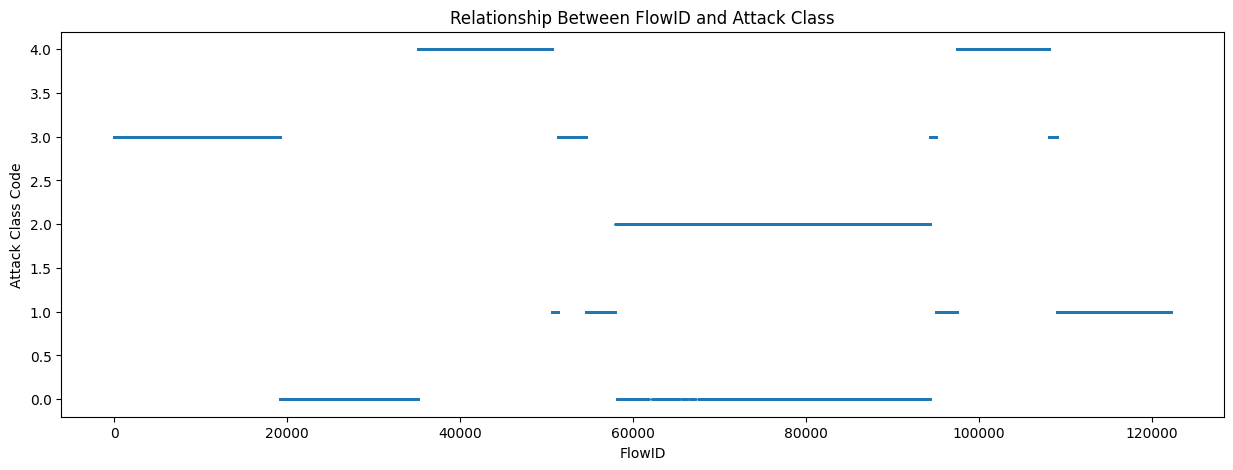

In [23]:
import matplotlib.pyplot as plt

temp = df.sort_values("FlowID").copy()

plt.figure(figsize=(15, 5))

plt.scatter(
    temp["FlowID"],
    temp['label'].astype("category").cat.codes,
    s=1
)

plt.xlabel("FlowID")
plt.ylabel("Attack Class Code")
plt.title("Relationship Between FlowID and Attack Class")

plt.show()

In [25]:
for col in ["SrcAddr", "DstAddr"]:

    print("\nFEATURE:", col)

    class_counts = (
        df.groupby(col)['label']
        .nunique()
    )

    print("\nAddresses by number of associated classes:")
    print(class_counts.value_counts().sort_index())

    print("\nSingle-class addresses:")
    print((class_counts == 1).sum())

    print("\nMulti-class addresses:")
    print((class_counts > 1).sum())


FEATURE: SrcAddr

Addresses by number of associated classes:
label
1    51
2    16
3    10
4    96
5     3
Name: count, dtype: int64

Single-class addresses:
51

Multi-class addresses:
125

FEATURE: DstAddr

Addresses by number of associated classes:
label
1    68
2    40
3    10
4    10
5    90
Name: count, dtype: int64

Single-class addresses:
68

Multi-class addresses:
150


In [26]:
# Address-label association summary

for col in ["SrcAddr", "DstAddr"]:

    print("\nFEATURE:", col)

    table = pd.crosstab(
        df[col],
        df['label']
    )

    # Total records associated with each address
    address_totals = table.sum(axis=1)

    # Number of records belonging to the most common class
    dominant_counts = table.max(axis=1)

    # Dominant class proportion for each address
    dominant_ratio = dominant_counts / address_totals

    print("Total unique addresses:", len(table))

    print(
        "Addresses with 100% single-class records:",
        (dominant_ratio == 1).sum()
    )

    print(
        "Addresses with at least 95% single-class records:",
        (dominant_ratio >= 0.95).sum()
    )


FEATURE: SrcAddr
Total unique addresses: 176
Addresses with 100% single-class records: 51
Addresses with at least 95% single-class records: 58

FEATURE: DstAddr
Total unique addresses: 218
Addresses with 100% single-class records: 68
Addresses with at least 95% single-class records: 68


In [ ]:
#Features (X) and target (y)
#X = df.drop(columns=[TARGET])
#y = df[TARGET]
# Convert text columns to numbers
#for col in X.select_dtypes(exclude="number").columns:
#  X[col] = LabelEncoder().fit_transform(X[col].astype(str))

#X.head(10)

In [ ]:
# Target: attack-এর নাম
y = df["label"]

# দুটি label-related column বাদ
X = df.drop(columns=["label", "target"])

# প্রথম পরীক্ষায় identifier বাদ দিন
X = X.drop(columns=["FlowID", "SrcAddr", "DstAddr"])

# প্রাথমিক পরীক্ষার জন্য শুধু numeric features
X = X.select_dtypes(include="number")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Train samples:", len(X_train))
print("Test samples:", len(X_test))
print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, zero_division=0))

Train samples: 97736
Test samples: 24435
Accuracy: 0.9519132392060569
                  precision    recall  f1-score   support

Blackhole Attack       0.93      0.87      0.90      5222
 Flooding Attack       1.00      0.99      0.99      3945
  Normal Traffic       0.99      0.99      0.99      5235
    Sybil Attack       0.99      1.00      1.00      4816
 Wormhole Attack       0.87      0.92      0.89      5217

        accuracy                           0.95     24435
       macro avg       0.96      0.95      0.95     24435
    weighted avg       0.95      0.95      0.95     24435



In [ ]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_pred  = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)   # probabilities -> needed for ROC/AUC

print(f"Random Forest | accuracy = {accuracy_score(y_test, rf_pred):.4f}")

Random Forest | accuracy = 0.9520


In [ ]:
## 8. Model 2: Extra Trees


# Extra Trees
et_model = ExtraTreesClassifier(n_estimators=600, random_state=RANDOM_STATE, n_jobs=-1)
et_model.fit(X_train, y_train)

et_pred  = et_model.predict(X_test)
et_proba = et_model.predict_proba(X_test)

print(f"Extra Trees | accuracy = {accuracy_score(y_test, et_pred):.4f}")

Extra Trees | accuracy = 0.9486


In [ ]:
# Map the text targets to numeric targets for XGBoost
y_train_numeric = y_train.map(label_mapping)
y_test_numeric = y_test.map(label_mapping)

xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=10,
    random_state=RANDOM_STATE
)
xgb_model.fit(X_train, y_train_numeric)

xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)

print(f"XGBoost | accuracy = {accuracy_score(y_test_numeric, xgb_pred):.4f}")

XGBoost | accuracy = 0.9545


In [ ]:
# LightGBM
lgb_model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=5,
                               random_state=RANDOM_STATE, verbose=-1)
lgb_model.fit(X_train, y_train)

lgb_pred  = lgb_model.predict(X_test)
lgb_proba = lgb_model.predict_proba(X_test)

print(f"LightGBM | accuracy = {accuracy_score(y_test, lgb_pred):.4f}")

LightGBM | accuracy = 0.9552


In [ ]:
# Map text targets to numeric values for CatBoost
y_train_numeric = y_train.map(label_mapping)
y_test_numeric = y_test.map(label_mapping)

# CatBoost
cat_model = CatBoostClassifier(iterations=500, learning_rate=0.1, depth=10,
                               random_state=RANDOM_STATE, verbose=0)
cat_model.fit(X_train, y_train_numeric)

cat_pred  = cat_model.predict(X_test).ravel().astype(int)   # flatten to 1-D labels
cat_proba = cat_model.predict_proba(X_test)

print(f"CatBoost | accuracy = {accuracy_score(y_test_numeric, cat_pred):.4f}")

CatBoost | accuracy = 0.9479


In [ ]:
# Stacking: 5 base models + Logistic Regression as the meta-model
stack_model = StackingClassifier(
    estimators=[("rf", rf_model), ("et", et_model), ("xgb", xgb_model),
                ("lgb", lgb_model), ("cat", cat_model)],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
)
stack_model.fit(X_train, y_train)

stack_pred  = stack_model.predict(X_test)
stack_proba = stack_model.predict_proba(X_test)

print(f"Stacking | accuracy = {accuracy_score(y_test, stack_pred):.4f}")

Stacking | accuracy = 1.0000


In [ ]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

target = "label"  # প্রকৃত target column-এর নাম দিন

print("\nClass distribution:")
print(df[target].value_counts(dropna=False))

print("\nPossible label-related columns:")
print([
    col for col in df.columns
    if any(word in col.lower()
           for word in ["label", "attack", "class", "target"])
])

Shape: (122171, 24)
Columns: ['FlowID', 'FlowDuration/s', 'SrcAddr', 'SrcPort', 'DstAddr', 'DstPort', 'Protocol', 'TxPackets', 'RxPackets', 'LostPackets', 'TxBytes', 'RxBytes', 'TxPacketRate/s', 'RxPacketRate/s', 'TxByteRate/s', 'RxByteRate/s', 'MeanDelay/s', 'MeanJitter/s', 'Throughput/Kbps', 'MeanPacketSize', 'PacketDropRate', 'AverageHopCount', 'label', 'target']

Class distribution:
label
Normal Traffic      26172
Blackhole Attack    26110
Wormhole Attack     26086
Sybil Attack        24077
Flooding Attack     19726
Name: count, dtype: int64

Possible label-related columns:
['label', 'target']


In [ ]:
print("label values:")
print(df["label"].value_counts(dropna=False))

print("\ntarget values:")
print(df["target"].value_counts(dropna=False))

print("\nLabel-target cross-tabulation:")
print(pd.crosstab(df["label"], df["target"]))

print("\nTarget unique values:")
print(df["target"].unique())

label values:
label
Normal Traffic      26172
Blackhole Attack    26110
Wormhole Attack     26086
Sybil Attack        24077
Flooding Attack     19726
Name: count, dtype: int64

target values:
target
0    26172
1    26110
2    26086
3    24077
4    19726
Name: count, dtype: int64

Label-target cross-tabulation:
target                0      1      2      3      4
label                                              
Blackhole Attack      0  26110      0      0      0
Flooding Attack       0      0      0      0  19726
Normal Traffic    26172      0      0      0      0
Sybil Attack          0      0      0  24077      0
Wormhole Attack       0      0  26086      0      0

Target unique values:
[3 1 2 4 0]
